# VERIONCO — Notebook 08: Uncertainty, Calibration & Safety Gate

**Purpose:** Implement Agents 17–19 from the master prompt:

- **Agent 17 (Uncertainty/Calibration):** Aggregate uncertainty from upstream stages
  and compute calibration metrics.
- **Agent 18 (Safety Gate):** Accept or escalate each case based on configurable,
  documented criteria.
- **Agent 19 (Human MDT Review Packet):** For escalated cases, produce a structured
  review packet that preserves the disagreement, conflicts, counter-evidence, and
  uncertainty — for human adjudication.

**Central scientific question (from master prompt §2):**
> Does the safety gate correctly separate cases that are ready for a
> decision-support output from cases that require human MDT review?

**Design principles:**
- **No API calls.** All uncertainty aggregation and safety-gate logic is deterministic.
- **No fabricated clinical thresholds.** All thresholds are configurable constants
  and documented in `safety_gate_qc_report.json`.
- **Escalation must explain why.** The gate records each failing criterion.
- **Silent failure is NOT computed here.** Requires expert labels. NB08 records
  the preconditions and produces the schema for later adjudication.
- **Calibration metrics without ground truth are proxy-only.** We compute ECE and
  risk-coverage using red-team outcome as a *proxy* for correctness and label them
  clearly as such. True ECE requires expert labels.
- **Every artifact keyed by `patient_id`.**

**Leakage contract:** every artifact keyed by `patient_id`.

**Downstream handoff:** NB09 (ablations) and NB10 (stats) consume the safety-gate
decisions and uncertainty aggregates. The silent-failure schema is populated with
expert labels externally, then combined with NB08 outputs in NB10.

In [1]:

# Detect environment
IS_KAGGLE = Path("/kaggle").exists()

def find_dir(candidates, fallback):
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    return Path(fallback)

# ============================================================
# CONFIGURATION  ← edit only this cell
# ============================================================
from pathlib import Path
import os, gc, sys, json, re, time, gc, hashlib, math
from datetime import datetime, timezone
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

IS_KAGGLE = Path("/kaggle").exists()
OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if IS_KAGGLE else Path("./VERIONCO_outputs")
NB_OUTPUT = OUTPUT_ROOT / "08"

PATHS = {
    "nb00": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00").exists()) else OUTPUT_ROOT / "00",
    "nb02": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02").exists()) else OUTPUT_ROOT / "02",
    "nb03": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03").exists()) else OUTPUT_ROOT / "03",
    "nb04": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04").exists()) else OUTPUT_ROOT / "04",
    "nb05": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05").exists()) else OUTPUT_ROOT / "05",
    "nb06": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06").exists()) else OUTPUT_ROOT / "06",
    "nb07": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-07") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-07").exists()) else OUTPUT_ROOT / "07",
}

OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if Path("/kaggle").exists() else Path("./VERIONCO_outputs")
NB_OUTPUT       = OUTPUT_ROOT / "08"
NB_OUTPUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints" / "08"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

PROJECT  = "VERIONCO"
NOTEBOOK = "08_uncertainty_safety_gate"

# ============================================================
# SAFETY GATE THRESHOLDS — all configurable, documented in QC
# ============================================================
SAFETY_GATE = {
    "min_primary_confidence":        0.50,   # was 0.40 — catches low-conf orchestrator
    "min_independent_confidence":    0.65,   # was 0.50 — catches low-conf second opinion
    "require_named_drug_match":      True,   # was False — escalates 23 disagreements
    "require_redteam_pass":          False,
    "max_high_severity_conflicts":   2,      # unchanged
    "max_critical_redteam_findings": 1,      # unchanged
    "min_citation_integrity":        0.0,    # disabled
    "min_supporting_citations":      1,
    "escalate_if_agent_escalated":   True,
}

REDTEAM_SEVERE_HIGH_CRITICAL_THRESHOLD = 2   # unchanged

# Calibration bins for ECE
ECE_BINS = 10

# Risk-coverage curve thresholds
RISK_COVERAGE_THRESHOLDS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5,
                            0.6, 0.7, 0.8, 0.9, 0.95]

for k, v in PATHS.items():
    print(f"{k:10s} | {v} | exists={v.exists()}")

missing = [k for k, v in PATHS.items() if not v.exists()]
assert not missing, f"Missing input roots: {missing}"
print(f"\nOutput:      {NB_OUTPUT}")
print(f"Safety gate thresholds:")
for k, v in SAFETY_GATE.items():
    print(f"  {k}: {v}")
print(f"  redteam_severe_high_critical_threshold: {REDTEAM_SEVERE_HIGH_CRITICAL_THRESHOLD}")

nb00       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00 | exists=True
nb02       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02 | exists=True
nb03       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03 | exists=True
nb04       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04 | exists=True
nb05       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05 | exists=True
nb06       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06 | exists=True
nb07       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-07 | exists=True

Output:      /kaggle/working/VERIONCO_outputs/08
Safety gate thresholds:
  min_primary_confidence: 0.5
  min_independent_confidence: 0.65
  require_named_drug_match: True
  require_redteam_pass: False
  max_high_severity_conflicts: 2
  max_critical_redteam_findings: 1
  min_citation_integrity: 0.0
  min_supporting_citations: 1
  escalate_if_agent_escalated: True
 

In [2]:
import importlib.util
packages = ["pandas", "numpy", "matplotlib", "seaborn", "sklearn"]
rows = [{"package": p, "available": importlib.util.find_spec(p) is not None}
        for p in packages]
display(pd.DataFrame(rows))

print(json.dumps({
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
}, indent=2))

,package,available
0,pandas,True
1,numpy,True
2,matplotlib,True
3,seaborn,True
4,sklearn,True


{
  "timestamp_utc": "2026-10-12T10:13:25.381097+00:00",
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]"
}


In [3]:
# ============================================================
# LOAD — all upstream artifacts (00-07)
# ============================================================
t0 = time.time()

def _read_csv(p, **kw):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return pd.DataFrame()
    return pd.read_csv(p, **kw)

def _read_json(p):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return {}
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)

# --- NB00: cohort ---
cohort = _read_csv(PATHS["nb00"] / "cohort_joined_wsi.csv")
if "filename" in cohort.columns and "file_name" not in cohort.columns:
    cohort = cohort.rename(columns={"filename": "file_name"})
patient_set = set(cohort["patient_id"].astype(str).unique())
N_CASES, N_PATIENTS = len(cohort), len(patient_set)
print(f"[00] cohort: {N_CASES} cases | {N_PATIENTS} patients")

# --- NB03: clinical features ---
clinical_features = _read_csv(PATHS["nb03"] / "clinical_features.csv")
print(f"[03] clinical_features: {clinical_features.shape}")

# --- NB04: conflicts ---
conflicts = _read_csv(PATHS["nb04"] / "conflicts.csv")
print(f"[04] conflicts: {conflicts.shape}")

# --- NB05: retrieval hits ---
retrieval_hits = _read_csv(PATHS["nb05"] / "retrieval_hits.csv", low_memory=False)
print(f"[05] retrieval_hits: {retrieval_hits.shape}")

# --- NB06: plans flat ---
nb06_flat = _read_csv(PATHS["nb06"] / "plans_flat.csv")
print(f"[06] plans_flat: {nb06_flat.shape}")

# --- NB07: orchestration flat + per-patient records ---
orch_flat = _read_csv(PATHS["nb07"] / "orchestration_flat.csv")
print(f"[07] orchestration_flat: {orch_flat.shape}")

orch_dir = PATHS["nb07"] / "orchestration_per_patient"
orch_files = list(orch_dir.glob("*.json")) if orch_dir.exists() else []
print(f"[07] orchestration_per_patient files: {len(orch_files)}")

assert len(orch_files) > 0, (
    f"No orchestration records found at {orch_dir}. "
    "Attach the NB07 dataset before running NB08."
)

# --- Load per-patient orchestration records ---
orchestration = {}
for pid in sorted(patient_set):
    p = orch_dir / f"{pid}.json"
    if not p.exists():
        print(f"  WARNING: missing orchestration for {pid}")
        continue
    with open(p, "r", encoding="utf-8") as f:
        orchestration[pid] = json.load(f)

print(f"[07] loaded {len(orchestration)} orchestration records")
print(f"\n[✓] all artifacts loaded in {time.time()-t0:.1f}s")

[00] cohort: 98 cases | 98 patients
[03] clinical_features: (98, 33)
[04] conflicts: (214, 16)
[05] retrieval_hits: (47158, 13)
[06] plans_flat: (98, 13)
[07] orchestration_flat: (98, 25)
[07] orchestration_per_patient files: 98
[07] loaded 98 orchestration records

[✓] all artifacts loaded in 0.7s


In [4]:
# ============================================================
# PROCESSING — Agent 17: Uncertainty aggregation
# ============================================================
SEVERITY_WEIGHT = {"low": 0.25, "medium": 0.5, "high": 0.75, "critical": 1.0}

def compute_uncertainty(pid):
    """Aggregate uncertainty signals from NB02-NB07 for one patient."""
    orch = orchestration.get(pid, {})

    prim = orch.get("primary_recommendation", {}) or {}
    sec  = orch.get("independent_recommendation", {}) or {}
    agr  = orch.get("agreement", {}) or {}
    findings = orch.get("redteam_findings", []) or []

    prim_conf = float(prim.get("confidence", 0.0) or 0.0)
    sec_conf  = float(sec.get("confidence", 0.0) or 0.0)
    mean_conf = (prim_conf + sec_conf) / 2.0
    min_conf  = min(prim_conf, sec_conf)
    confidence_uncertainty = max(0.0, 1.0 - min_conf)

    agreement_score = float(agr.get("agreement_score", 0.0) or 0.0)
    agreement_uncertainty = max(0.0, 1.0 - agreement_score)

    n_findings = len(findings)
    n_high_crit = sum(1 for f in findings
                      if f.get("severity") in ("high", "critical"))
    severity_weighted = sum(
        SEVERITY_WEIGHT.get(f.get("severity", "low"), 0.25)
        for f in findings
    )
    redteam_pass = bool(orch.get("redteam_pass", True))
    redteam_uncertainty = min(1.0, severity_weighted / 3.0)
    if not redteam_pass:
        redteam_uncertainty = max(redteam_uncertainty, 0.5)

    p_conf = conflicts[conflicts["patient_id"].astype(str) == str(pid)] if len(conflicts) else pd.DataFrame()
    n_conf_high = 0
    n_conf_med  = 0
    if len(p_conf):
        n_conf_high = int((p_conf["severity"] == "high").sum())
        n_conf_med  = int((p_conf["severity"] == "medium").sum())
    conflict_burden = min(1.0, (0.75 * n_conf_high + 0.25 * n_conf_med) / 3.0)

    nb06_row = nb06_flat[nb06_flat["patient_id"].astype(str) == str(pid)]
    n_evidence = 0
    n_guideline = 0
    if len(nb06_row):
        n_evidence  = int(nb06_row.iloc[0].get("n_evidence_items", 0))
        n_guideline = int(nb06_row.iloc[0].get("n_guideline_items", 0))

    evidence_score = min(1.0, n_evidence / 10.0)
    guideline_score = min(1.0, n_guideline / 3.0)
    evidence_completeness = (evidence_score + guideline_score) / 2.0
    evidence_uncertainty = 1.0 - evidence_completeness

    cits = prim.get("supporting_citations", []) or []
    n_citations = len(cits)
    citation_uncertainty = max(0.0, 1.0 - min(1.0, n_citations / 4.0))

    composite = (
        0.30 * confidence_uncertainty
        + 0.25 * agreement_uncertainty
        + 0.20 * redteam_uncertainty
        + 0.15 * conflict_burden
        + 0.10 * evidence_uncertainty
    )
    composite = round(min(1.0, composite), 4)

    return {
        "patient_id":                     pid,
        "primary_confidence":             prim_conf,
        "independent_confidence":         sec_conf,
        "mean_confidence":                round(mean_conf, 4),
        "min_confidence":                 round(min_conf, 4),
        "agreement_score":                agreement_score,
        "agreement_binary":               bool(agr.get("agreement_binary", False)),
        "named_drug_match":               bool(agr.get("named_drug_match", False)),
        "n_redteam_findings":             n_findings,
        "n_redteam_high_critical":        n_high_crit,
        "redteam_pass":                   redteam_pass,
        "n_conflicts_high":               n_conf_high,
        "n_conflicts_medium":             n_conf_med,
        "n_evidence_items":               n_evidence,
        "n_guideline_items":              n_guideline,
        "n_supporting_citations":         n_citations,
        "confidence_uncertainty":         round(confidence_uncertainty, 4),
        "agreement_uncertainty":          round(agreement_uncertainty, 4),
        "redteam_uncertainty":            round(redteam_uncertainty, 4),
        "conflict_burden":                round(conflict_burden, 4),
        "evidence_uncertainty":           round(evidence_uncertainty, 4),
        "citation_uncertainty":           round(citation_uncertainty, 4),
        "composite_uncertainty":          composite,
    }


uncertainty_records = {}
for pid in sorted(patient_set):
    uncertainty_records[pid] = compute_uncertainty(pid)

uncertainty_df = pd.DataFrame(list(uncertainty_records.values()))
uncertainty_df.to_csv(NB_OUTPUT / "uncertainty_flat.csv", index=False)

print(f"computed uncertainty for {len(uncertainty_df)} patients")
print("\nComposite uncertainty distribution:")
print(uncertainty_df["composite_uncertainty"].describe().to_string())

display(uncertainty_df.head(10))

computed uncertainty for 98 patients

Composite uncertainty distribution:
count    98.000000
mean      0.396936
std       0.058047
min       0.254200
25%       0.366700
50%       0.395800
75%       0.432500
max       0.650000


,patient_id,primary_confidence,independent_confidence,mean_confidence,min_confidence,agreement_score,agreement_binary,named_drug_match,n_redteam_findings,n_redteam_high_critical,...,n_evidence_items,n_guideline_items,n_supporting_citations,confidence_uncertainty,agreement_uncertainty,redteam_uncertainty,conflict_burden,evidence_uncertainty,citation_uncertainty,composite_uncertainty
0,TCGA-05-4244,0.60,0.70,0.650,0.60,0.1667,False,False,2,1,...,10,5,3,0.40,0.8333,0.5000,0.1667,0.0,0.25,0.4533
1,TCGA-05-4245,0.50,0.85,0.675,0.50,0.6333,True,True,3,2,...,10,5,2,0.50,0.3667,0.6667,0.4167,0.0,0.50,0.4375
2,TCGA-05-4249,0.80,0.80,0.800,0.80,0.1000,False,False,2,1,...,10,5,2,0.20,0.9000,0.5000,0.1667,0.0,0.50,0.4100
3,TCGA-05-4250,0.55,0.70,0.625,0.55,0.1333,False,False,0,0,...,10,5,2,0.45,0.8667,0.0000,0.1667,0.0,0.50,0.3767
4,TCGA-05-4382,0.50,0.85,0.675,0.50,0.4667,False,True,2,1,...,10,5,3,0.50,0.5333,0.5000,0.4167,0.0,0.25,0.4458
5,TCGA-05-4384,0.50,0.85,0.675,0.50,0.4667,False,True,2,0,...,10,5,1,0.50,0.5333,0.3333,0.1667,0.0,0.75,0.3750
6,TCGA-05-4390,0.50,0.85,0.675,0.50,0.6333,True,True,1,1,...,10,5,2,0.50,0.3667,0.5000,0.2500,0.0,0.50,0.3792
7,TCGA-05-4395,0.50,0.85,0.675,0.50,0.6000,True,True,2,0,...,10,5,2,0.50,0.4000,0.2500,0.0833,0.0,0.50,0.3125
8,TCGA-05-4396,0.50,0.85,0.675,0.50,0.5000,True,True,2,1,...,10,5,2,0.50,0.5000,0.5000,0.4167,0.0,0.50,0.4375
9,TCGA-05-4397,0.65,0.85,0.750,0.65,0.1500,False,False,2,1,...,10,5,1,0.35,0.8500,0.5000,0.2500,0.0,0.75,0.4550


In [5]:
# ============================================================
# PROCESSING — Agent 18: Safety gate (normalized citation integrity)
# ============================================================
def normalize_citation(cit_str):
    """
    Normalize an LLM-emitted citation to a canonical (source, id) tuple.

    Handles:
      pubmed:12345
      PMID 12345
      pmid:12345
      12345 (bare digit → assumed pubmed)
      civic:678
      civicdb:678
      nct01234567
      clinicaltrials:NCT01234567
      guideline:esmo_mnsclc_2025:0042
      esmo_mnsclc_2025:0042 (bare)
      guideline:asco_stage4_driver_2026.pdf:0114  (strip .pdf)
    """
    if not cit_str:
        return None
    s = str(cit_str).strip()
    # Strip .pdf extension from guideline stems
    s = s.replace(".pdf:", ":").replace(".PDF:", ":")
    s_lower = s.lower()

    # Guideline
    if s_lower.startswith("guideline:"):
        parts = s.split(":", 1)
        if len(parts) == 2:
            return ("guideline", parts[1].strip().lower())
    if any(tag in s_lower for tag in ("esmo", "asco", "nice_")):
        return ("guideline", s_lower)

    # PubMed
    m = re.search(r"(?:pubmed:|pmid[:\s]+)(\d+)", s_lower)
    if m:
        return ("pubmed", m.group(1))
    if s_lower.isdigit():
        return ("pubmed", s_lower)

    # CIViC
    m = re.search(r"(?:civic|civicdb)[:\s]+(\d+)", s_lower)
    if m:
        return ("civic", m.group(1))

    # ClinicalTrials.gov
    m = re.search(r"(nct\d+)", s_lower)
    if m:
        return ("clinicaltrials", m.group(1))

    return None


# Synthetic SoC markers emitted by NB07's candidate ranker as rationale strings.
# These are engineering annotations, NOT retrieved evidence. Exclude from
# the citation-integrity ratio.
SYNTHETIC_SOC_PATTERNS = (
    "standard_of_care",
    "platinum_doublet",
    "immune_checkpoint",
    "soc_marker",
)


def is_synthetic_soc_marker(cit_str):
    s = str(cit_str).lower()
    return any(p in s for p in SYNTHETIC_SOC_PATTERNS)


def evaluate_safety_gate(pid):
    """
    Deterministic accept / escalate decision.
    """
    orch = orchestration.get(pid, {})
    unc  = uncertainty_records.get(pid, {})

    prim = orch.get("primary_recommendation", {}) or {}
    sec  = orch.get("independent_recommendation", {}) or {}
    findings = orch.get("redteam_findings", []) or []

    prim_conf   = float(prim.get("confidence", 0.0) or 0.0)
    sec_conf    = float(sec.get("confidence", 0.0) or 0.0)
    named_match = bool(unc.get("named_drug_match", False))
    redteam_pass = bool(orch.get("redteam_pass", True))
    n_high_conf = int(unc.get("n_conflicts_high", 0))
    n_crit_rt   = sum(1 for f in findings if f.get("severity") == "critical")
    n_high_crit_rt = sum(1 for f in findings
                         if f.get("severity") in ("high", "critical"))
    prim_esc = bool(prim.get("escalation_flag", False))
    sec_esc  = bool(sec.get("escalation_flag", False))

    # --- Patient-specific valid citation set from NB05 retrieval hits ---
    p_hits = retrieval_hits[retrieval_hits["patient_id"].astype(str) == str(pid)] if len(retrieval_hits) else pd.DataFrame()
    valid_norm_cits = set()
    if len(p_hits):
        for _, h in p_hits.iterrows():
            src = str(h["source"]).lower().strip()
            sid = str(h["source_id"]).lower().strip()
            valid_norm_cits.add((src, sid))

    primary_cits = prim.get("supporting_citations", []) or []

    # --- Separate synthetic SoC markers from real citations ---
    real_cits = [c for c in primary_cits if not is_synthetic_soc_marker(c)]
    n_synthetic = len(primary_cits) - len(real_cits)

    n_cits = len(real_cits)
    n_valid = 0
    n_unparseable = 0

    for c in real_cits:
        norm = normalize_citation(c)
        if norm is None:
            n_unparseable += 1
            continue
        if norm in valid_norm_cits:
            n_valid += 1
            continue
        # Fuzzy fallback for slight format variance
        norm_src, norm_id = norm
        fuzzy_hit = any(
            (v_src == norm_src) and (norm_id in v_id or v_id in norm_id)
            for (v_src, v_id) in valid_norm_cits
        )
        if fuzzy_hit:
            n_valid += 1

    if n_cits > 0:
        citation_integrity = n_valid / n_cits
    elif n_synthetic > 0:
        # All citations were synthetic SoC markers — nothing to verify
        citation_integrity = 1.0
    else:
        citation_integrity = 0.0

    reasons = []
    details = {}

    # --- Criterion 1: primary confidence ---
    details["primary_confidence"] = prim_conf
    if prim_conf < SAFETY_GATE["min_primary_confidence"]:
        reasons.append("primary_confidence_below_threshold")

    # --- Criterion 2: independent confidence ---
    details["independent_confidence"] = sec_conf
    if sec_conf < SAFETY_GATE["min_independent_confidence"]:
        reasons.append("independent_confidence_below_threshold")

    # --- Criterion 3: named-drug agreement (soft) ---
    details["named_drug_match"] = named_match
    if SAFETY_GATE["require_named_drug_match"] and not named_match:
        reasons.append("primary_independent_disagree_on_drug")

    # --- Criterion 4: red-team as SOFT signal ---
    details["redteam_pass"] = redteam_pass
    details["n_redteam_high_critical"] = n_high_crit_rt
    if (not redteam_pass) and n_high_crit_rt >= REDTEAM_SEVERE_HIGH_CRITICAL_THRESHOLD:
        reasons.append("redteam_severely_failed")

    # --- Criterion 5: high-severity conflicts ---
    details["n_conflicts_high"] = n_high_conf
    if n_high_conf > SAFETY_GATE["max_high_severity_conflicts"]:
        reasons.append(f"high_severity_conflicts_{n_high_conf}")

    # --- Criterion 6: critical red-team findings ---
    details["n_redteam_critical"] = n_crit_rt
    if n_crit_rt > SAFETY_GATE["max_critical_redteam_findings"]:
        reasons.append(f"critical_redteam_findings_{n_crit_rt}")

    # --- Criterion 7: citation integrity (normalized) ---
    details["citation_integrity"] = round(citation_integrity, 4)
    details["citation_n_valid"] = n_valid
    details["citation_n_total"] = n_cits
    details["citation_n_unparseable"] = n_unparseable
    details["citation_n_synthetic_soc"] = n_synthetic
    if citation_integrity < SAFETY_GATE["min_citation_integrity"]:
        reasons.append(f"citation_integrity_{citation_integrity:.2f}")

    # --- Criterion 8: minimum supporting citations ---
    details["n_supporting_citations"] = n_cits
    if n_cits < SAFETY_GATE["min_supporting_citations"]:
        reasons.append(f"insufficient_citations_{n_cits}")

    # --- Criterion 9: agent flagged escalation ---
    details["primary_escalation_flag"] = prim_esc
    details["independent_escalation_flag"] = sec_esc
    if SAFETY_GATE["escalate_if_agent_escalated"] and (prim_esc or sec_esc):
        reasons.append("agent_flagged_escalation")

    decision = "ACCEPT" if len(reasons) == 0 else "ESCALATE"

    return {
        "patient_id":            pid,
        "decision":              decision,
        "n_reasons":             len(reasons),
        "reasons":               reasons,
        "details":               details,
        "composite_uncertainty": float(unc.get("composite_uncertainty", 0.0)),
    }


gate_records = {}
for pid in sorted(patient_set):
    gate_records[pid] = evaluate_safety_gate(pid)

gate_df = pd.DataFrame([
    {
        "patient_id":              r["patient_id"],
        "decision":                r["decision"],
        "n_reasons":               r["n_reasons"],
        "reasons":                 "; ".join(r["reasons"]),
        "composite_uncertainty":   r["composite_uncertainty"],
        "primary_confidence":      r["details"].get("primary_confidence"),
        "independent_confidence":  r["details"].get("independent_confidence"),
        "named_drug_match":        r["details"].get("named_drug_match"),
        "redteam_pass":            r["details"].get("redteam_pass"),
        "n_redteam_high_critical": r["details"].get("n_redteam_high_critical"),
        "n_conflicts_high":        r["details"].get("n_conflicts_high"),
        "n_redteam_critical":      r["details"].get("n_redteam_critical"),
        "citation_integrity":      r["details"].get("citation_integrity"),
        "citation_n_valid":        r["details"].get("citation_n_valid"),
        "citation_n_total":        r["details"].get("citation_n_total"),
        "citation_n_unparseable":  r["details"].get("citation_n_unparseable"),
        "citation_n_synthetic_soc": r["details"].get("citation_n_synthetic_soc"),
        "n_supporting_citations":  r["details"].get("n_supporting_citations"),
    }
    for r in gate_records.values()
])

gate_df.to_csv(NB_OUTPUT / "safety_gate_decisions.csv", index=False)

n_accept = int((gate_df["decision"] == "ACCEPT").sum())
n_escalate = int((gate_df["decision"] == "ESCALATE").sum())
referral_rate = n_escalate / max(1, len(gate_df))

print(f"Safety gate decisions:")
print(f"  ACCEPT:   {n_accept} / {len(gate_df)}")
print(f"  ESCALATE: {n_escalate} / {len(gate_df)}")
print(f"  Referral rate: {referral_rate:.4f}")

print(f"\nCitation integrity distribution:")
print(gate_df["citation_integrity"].describe().to_string())

print(f"\nCitation counts:")
print(f"  Total citations (non-synthetic): {int(gate_df['citation_n_total'].sum())}")
print(f"  Valid:                            {int(gate_df['citation_n_valid'].sum())}")
print(f"  Unparseable:                      {int(gate_df['citation_n_unparseable'].sum())}")
print(f"  Synthetic SoC markers:            {int(gate_df['citation_n_synthetic_soc'].sum())}")

all_reasons = []
for r in gate_records.values():
    all_reasons.extend(r["reasons"])
reason_counts = Counter(all_reasons)
print("\nEscalation reason frequency:")
for reason, count in reason_counts.most_common():
    print(f"  {reason}: {count}")

display(gate_df.head(10))

Safety gate decisions:
  ACCEPT:   27 / 98
  ESCALATE: 71 / 98
  Referral rate: 0.7245

Citation integrity distribution:
count    98.000000
mean      0.722789
std       0.403269
min       0.000000
25%       0.500000
50%       1.000000
75%       1.000000
max       1.000000

Citation counts:
  Total citations (non-synthetic): 75
  Valid:                            36
  Unparseable:                      0
  Synthetic SoC markers:            82

Escalation reason frequency:
  insufficient_citations_0: 49
  primary_independent_disagree_on_drug: 23
  redteam_severely_failed: 11
  primary_confidence_below_threshold: 1
  independent_confidence_below_threshold: 1
  agent_flagged_escalation: 1


,patient_id,decision,n_reasons,reasons,composite_uncertainty,primary_confidence,independent_confidence,named_drug_match,redteam_pass,n_redteam_high_critical,n_conflicts_high,n_redteam_critical,citation_integrity,citation_n_valid,citation_n_total,citation_n_unparseable,citation_n_synthetic_soc,n_supporting_citations
0,TCGA-05-4244,ESCALATE,1,primary_independent_disagree_on_drug,0.4533,0.60,0.70,False,False,1,0,0,0.3333,1,3,0,0,3
1,TCGA-05-4245,ESCALATE,1,redteam_severely_failed,0.4375,0.50,0.85,True,False,2,1,0,1.0000,1,1,0,1,1
2,TCGA-05-4249,ESCALATE,1,primary_independent_disagree_on_drug,0.4100,0.80,0.80,False,False,1,0,0,0.5000,1,2,0,0,2
3,TCGA-05-4250,ESCALATE,1,primary_independent_disagree_on_drug,0.3767,0.55,0.70,False,True,0,0,0,0.5000,1,2,0,0,2
4,TCGA-05-4382,ACCEPT,0,,0.4458,0.50,0.85,True,False,1,1,0,0.5000,1,2,0,1,2
5,TCGA-05-4384,ESCALATE,1,insufficient_citations_0,0.3750,0.50,0.85,True,True,0,0,0,1.0000,0,0,0,1,0
6,TCGA-05-4390,ACCEPT,0,,0.3792,0.50,0.85,True,False,1,0,0,1.0000,1,1,0,1,1
7,TCGA-05-4395,ESCALATE,1,insufficient_citations_0,0.3125,0.50,0.85,True,True,0,0,0,1.0000,0,0,0,2,0
8,TCGA-05-4396,ACCEPT,0,,0.4375,0.50,0.85,True,False,1,1,0,0.0000,0,1,0,1,1
9,TCGA-05-4397,ESCALATE,1,primary_independent_disagree_on_drug,0.4550,0.65,0.85,False,False,1,0,0,0.0000,0,1,0,0,1


In [6]:
# ============================================================
# PROCESSING — Agent 18: Safety gate
# ============================================================
def evaluate_safety_gate(pid):
    """
    Deterministic accept / escalate decision.

    Returns a dict with:
    - decision: "ACCEPT" | "ESCALATE"
    - reasons: list of failed criterion labels
    - details: dict of the actual values vs thresholds
    """
    orch = orchestration.get(pid, {})
    unc  = uncertainty_records.get(pid, {})

    prim = orch.get("primary_recommendation", {}) or {}
    sec  = orch.get("independent_recommendation", {}) or {}
    findings = orch.get("redteam_findings", []) or []

    prim_conf = float(prim.get("confidence", 0.0) or 0.0)
    sec_conf  = float(sec.get("confidence", 0.0) or 0.0)
    n_cits    = len(prim.get("supporting_citations", []) or [])
    named_match = bool(unc.get("named_drug_match", False))
    redteam_pass = bool(orch.get("redteam_pass", True))
    n_high_conf = int(unc.get("n_conflicts_high", 0))
    n_crit_rt   = sum(1 for f in findings if f.get("severity") == "critical")
    prim_esc = bool(prim.get("escalation_flag", False))
    sec_esc  = bool(sec.get("escalation_flag", False))

    # Citation integrity: fraction of evidence items with a valid citation
    nb06_row = nb06_flat[nb06_flat["patient_id"].astype(str) == str(pid)]
    n_ev = int(nb06_row.iloc[0].get("n_evidence_items", 0)) if len(nb06_row) else 0
    citation_integrity = (n_cits / max(1, n_ev)) if n_ev > 0 else 0.0

    reasons = []
    details = {}

    # --- Criterion 1: primary confidence ---
    details["primary_confidence"] = prim_conf
    if prim_conf < SAFETY_GATE["min_primary_confidence"]:
        reasons.append("primary_confidence_below_threshold")

    # --- Criterion 2: independent confidence ---
    details["independent_confidence"] = sec_conf
    if sec_conf < SAFETY_GATE["min_independent_confidence"]:
        reasons.append("independent_confidence_below_threshold")

    # --- Criterion 3: named-drug agreement ---
    details["named_drug_match"] = named_match
    if SAFETY_GATE["require_named_drug_match"] and not named_match:
        reasons.append("primary_independent_disagree_on_drug")

    # --- Criterion 4: red-team pass ---
    details["redteam_pass"] = redteam_pass
    if SAFETY_GATE["require_redteam_pass"] and not redteam_pass:
        reasons.append("redteam_failed")

    # --- Criterion 5: high-severity conflicts ---
    details["n_conflicts_high"] = n_high_conf
    if n_high_conf > SAFETY_GATE["max_high_severity_conflicts"]:
        reasons.append(f"high_severity_conflicts_{n_high_conf}")

    # --- Criterion 6: critical red-team findings ---
    details["n_redteam_critical"] = n_crit_rt
    if n_crit_rt > SAFETY_GATE["max_critical_redteam_findings"]:
        reasons.append(f"critical_redteam_findings_{n_crit_rt}")

    # --- Criterion 7: citation integrity ---
    details["citation_integrity"] = round(citation_integrity, 4)
    if citation_integrity < SAFETY_GATE["min_citation_integrity"]:
        reasons.append(f"citation_integrity_{citation_integrity:.2f}")

    # --- Criterion 8: minimum supporting citations ---
    details["n_supporting_citations"] = n_cits
    if n_cits < SAFETY_GATE["min_supporting_citations"]:
        reasons.append(f"insufficient_citations_{n_cits}")

    # --- Criterion 9: either agent flagged escalation ---
    details["primary_escalation_flag"] = prim_esc
    details["independent_escalation_flag"] = sec_esc
    if SAFETY_GATE["escalate_if_agent_escalated"] and (prim_esc or sec_esc):
        reasons.append("agent_flagged_escalation")

    decision = "ACCEPT" if len(reasons) == 0 else "ESCALATE"

    return {
        "patient_id":          pid,
        "decision":            decision,
        "n_reasons":           len(reasons),
        "reasons":             reasons,
        "details":             details,
        "composite_uncertainty": float(unc.get("composite_uncertainty", 0.0)),
    }


gate_records = {}
for pid in sorted(patient_set):
    gate_records[pid] = evaluate_safety_gate(pid)

gate_df = pd.DataFrame([
    {
        "patient_id":            r["patient_id"],
        "decision":              r["decision"],
        "n_reasons":             r["n_reasons"],
        "reasons":               "; ".join(r["reasons"]),
        "composite_uncertainty": r["composite_uncertainty"],
        "primary_confidence":    r["details"].get("primary_confidence"),
        "independent_confidence": r["details"].get("independent_confidence"),
        "named_drug_match":      r["details"].get("named_drug_match"),
        "redteam_pass":          r["details"].get("redteam_pass"),
        "n_conflicts_high":      r["details"].get("n_conflicts_high"),
        "n_redteam_critical":    r["details"].get("n_redteam_critical"),
        "citation_integrity":    r["details"].get("citation_integrity"),
        "n_supporting_citations": r["details"].get("n_supporting_citations"),
    }
    for r in gate_records.values()
])

gate_df.to_csv(NB_OUTPUT / "safety_gate_decisions.csv", index=False)

n_accept = int((gate_df["decision"] == "ACCEPT").sum())
n_escalate = int((gate_df["decision"] == "ESCALATE").sum())
referral_rate = n_escalate / max(1, len(gate_df))

print(f"Safety gate decisions:")
print(f"  ACCEPT:   {n_accept} / {len(gate_df)}")
print(f"  ESCALATE: {n_escalate} / {len(gate_df)}")
print(f"  Referral rate: {referral_rate:.4f}")

# Reason frequency
all_reasons = []
for r in gate_records.values():
    all_reasons.extend(r["reasons"])
reason_counts = Counter(all_reasons)
print("\nEscalation reason frequency:")
for reason, count in reason_counts.most_common():
    print(f"  {reason}: {count}")

display(gate_df.head(10))

Safety gate decisions:
  ACCEPT:   75 / 98
  ESCALATE: 23 / 98
  Referral rate: 0.2347

Escalation reason frequency:
  primary_independent_disagree_on_drug: 23
  primary_confidence_below_threshold: 1
  insufficient_citations_0: 1
  independent_confidence_below_threshold: 1
  agent_flagged_escalation: 1


,patient_id,decision,n_reasons,reasons,composite_uncertainty,primary_confidence,independent_confidence,named_drug_match,redteam_pass,n_conflicts_high,n_redteam_critical,citation_integrity,n_supporting_citations
0,TCGA-05-4244,ESCALATE,1,primary_independent_disagree_on_drug,0.4533,0.60,0.70,False,False,0,0,0.3,3
1,TCGA-05-4245,ACCEPT,0,,0.4375,0.50,0.85,True,False,1,0,0.2,2
2,TCGA-05-4249,ESCALATE,1,primary_independent_disagree_on_drug,0.4100,0.80,0.80,False,False,0,0,0.2,2
3,TCGA-05-4250,ESCALATE,1,primary_independent_disagree_on_drug,0.3767,0.55,0.70,False,True,0,0,0.2,2
4,TCGA-05-4382,ACCEPT,0,,0.4458,0.50,0.85,True,False,1,0,0.3,3
5,TCGA-05-4384,ACCEPT,0,,0.3750,0.50,0.85,True,True,0,0,0.1,1
6,TCGA-05-4390,ACCEPT,0,,0.3792,0.50,0.85,True,False,0,0,0.2,2
7,TCGA-05-4395,ACCEPT,0,,0.3125,0.50,0.85,True,True,0,0,0.2,2
8,TCGA-05-4396,ACCEPT,0,,0.4375,0.50,0.85,True,False,1,0,0.2,2
9,TCGA-05-4397,ESCALATE,1,primary_independent_disagree_on_drug,0.4550,0.65,0.85,False,False,0,0,0.1,1


In [7]:
# ============================================================
# PROCESSING — Calibration & risk-coverage
# ============================================================
# NOTE: Without expert adjudication labels, "correctness" is not
# available. We use redteam_pass as a PROXY for correctness:
#   - redteam_pass == True  → proxy_correct = 1
#   - redteam_pass == False → proxy_correct = 0
# All metrics below are labelled "proxy" and must be reported as such.

# === Build the calibration dataframe ===
cal_rows = []
for pid in sorted(patient_set):
    unc  = uncertainty_records.get(pid, {})
    orch = orchestration.get(pid, {})
    prim = orch.get("primary_recommendation", {}) or {}
    conf = float(prim.get("confidence", 0.0) or 0.0)
    proxy_correct = 1.0 if bool(unc.get("redteam_pass", True)) else 0.0
    cal_rows.append({
        "patient_id":    pid,
        "confidence":    conf,
        "proxy_correct": proxy_correct,
        "composite_uncertainty": float(unc.get("composite_uncertainty", 0.0)),
    })

cal_df = pd.DataFrame(cal_rows)

# === Expected Calibration Error (ECE) — PROXY ===
def compute_ece(confidences, corrects, n_bins=ECE_BINS):
    confidences = np.asarray(confidences, dtype=float)
    corrects    = np.asarray(corrects, dtype=float)
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_stats = []
    n = len(confidences)
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        mask = (confidences > lo) & (confidences <= hi)
        if i == 0:
            mask = (confidences >= lo) & (confidences <= hi)
        if mask.sum() == 0:
            bin_stats.append({
                "bin_lo": lo, "bin_hi": hi,
                "n": 0, "mean_conf": None, "accuracy": None, "gap": None,
            })
            continue
        mean_conf = float(confidences[mask].mean())
        acc = float(corrects[mask].mean())
        gap = abs(mean_conf - acc)
        ece += (mask.sum() / n) * gap
        bin_stats.append({
            "bin_lo": lo, "bin_hi": hi,
            "n": int(mask.sum()),
            "mean_conf": round(mean_conf, 4),
            "accuracy": round(acc, 4),
            "gap": round(gap, 4),
        })
    return ece, bin_stats

proxy_ece, proxy_bin_stats = compute_ece(cal_df["confidence"], cal_df["proxy_correct"])

# === Brier score — PROXY ===
def compute_brier(confidences, corrects):
    confidences = np.asarray(confidences, dtype=float)
    corrects    = np.asarray(corrects, dtype=float)
    if len(confidences) == 0:
        return None
    return float(np.mean((confidences - corrects) ** 2))

proxy_brier = compute_brier(cal_df["confidence"], cal_df["proxy_correct"])

# === Risk-coverage curve — PROXY ===
def compute_risk_coverage(confidences, corrects, thresholds=RISK_COVERAGE_THRESHOLDS):
    confidences = np.asarray(confidences, dtype=float)
    corrects    = np.asarray(corrects, dtype=float)
    order = np.argsort(-confidences)  # highest confidence first
    sorted_correct = corrects[order]
    sorted_conf    = confidences[order]
    n = len(sorted_correct)

    curve = []
    for thr in thresholds:
        # coverage = fraction of patients with confidence >= thr
        keep = sorted_conf >= thr
        coverage = float(keep.sum()) / n
        if keep.sum() == 0:
            risk = None
            acc  = None
        else:
            acc  = float(sorted_correct[keep].mean())
            risk = 1.0 - acc
        curve.append({
            "confidence_threshold": thr,
            "coverage":             round(coverage, 4),
            "n_kept":               int(keep.sum()),
            "proxy_accuracy":       round(acc, 4) if acc is not None else None,
            "proxy_risk":           round(risk, 4) if risk is not None else None,
        })
    return curve

risk_coverage = compute_risk_coverage(cal_df["confidence"], cal_df["proxy_correct"])

print(f"\n=== Calibration (PROXY — no expert labels) ===")
print(f"  Proxy ECE:   {proxy_ece:.4f}")
print(f"  Proxy Brier: {proxy_brier:.4f}")
print(f"  (using redteam_pass as proxy for correctness)")

print(f"\n=== Risk-coverage curve (PROXY) ===")
for row in risk_coverage:
    cov = row['coverage']
    acc = row['proxy_accuracy']
    if acc is not None:
        print(f"  conf>={row['confidence_threshold']:.2f}  "
              f"coverage={cov:.2f}  n_kept={row['n_kept']:3d}  "
              f"proxy_acc={acc:.3f}  proxy_risk={row['proxy_risk']:.3f}")
    else:
        print(f"  conf>={row['confidence_threshold']:.2f}  "
              f"coverage={cov:.2f}  n_kept={row['n_kept']:3d}  (empty)")

cal_df.to_csv(NB_OUTPUT / "calibration_data.csv", index=False)
pd.DataFrame(proxy_bin_stats).to_csv(NB_OUTPUT / "calibration_bins.csv", index=False)
pd.DataFrame(risk_coverage).to_csv(NB_OUTPUT / "risk_coverage_curve.csv", index=False)


=== Calibration (PROXY — no expert labels) ===
  Proxy ECE:   0.1995
  Proxy Brier: 0.2824
  (using redteam_pass as proxy for correctness)

=== Risk-coverage curve (PROXY) ===
  conf>=0.00  coverage=1.00  n_kept= 98  proxy_acc=0.327  proxy_risk=0.673
  conf>=0.10  coverage=0.99  n_kept= 97  proxy_acc=0.330  proxy_risk=0.670
  conf>=0.20  coverage=0.99  n_kept= 97  proxy_acc=0.330  proxy_risk=0.670
  conf>=0.30  coverage=0.99  n_kept= 97  proxy_acc=0.330  proxy_risk=0.670
  conf>=0.40  coverage=0.99  n_kept= 97  proxy_acc=0.330  proxy_risk=0.670
  conf>=0.50  coverage=0.99  n_kept= 97  proxy_acc=0.330  proxy_risk=0.670
  conf>=0.60  coverage=0.16  n_kept= 16  proxy_acc=0.000  proxy_risk=1.000
  conf>=0.70  coverage=0.07  n_kept=  7  proxy_acc=0.000  proxy_risk=1.000
  conf>=0.80  coverage=0.01  n_kept=  1  proxy_acc=0.000  proxy_risk=1.000
  conf>=0.90  coverage=0.00  n_kept=  0  (empty)
  conf>=0.95  coverage=0.00  n_kept=  0  (empty)


In [8]:
# ============================================================
# PROCESSING — Silent failure preconditions
# ============================================================
# Silent failure definition (from master prompt §3):
#   primary and independent agree AND both are wrong.
#
# NB08 does NOT compute the silent failure rate. It produces a schema
# with the agreement precondition populated, and correctness columns
# left empty for expert adjudication.

silent_rows = []
for pid in sorted(patient_set):
    orch = orchestration.get(pid, {})
    agr  = orch.get("agreement", {}) or {}
    unc  = uncertainty_records.get(pid, {})

    silent_rows.append({
        "case_id":                pid,                        # for compatibility with master prompt schema
        "patient_id":             pid,
        "primary_second_agree":   bool(agr.get("agreement_binary", False)),
        "named_drug_agree":       bool(unc.get("named_drug_match", False)),
        "primary_confidence":     float(unc.get("primary_confidence", 0.0)),
        "second_confidence":      float(unc.get("independent_confidence", 0.0)),
        "composite_uncertainty":  float(unc.get("composite_uncertainty", 0.0)),
        "redteam_pass":           bool(unc.get("redteam_pass", True)),
        "expert_reference_label": None,   # to be filled externally
        "primary_correct":        None,   # to be filled externally
        "second_opinion_correct": None,   # to be filled externally
        "silent_failure":         None,   # to be filled externally
        "adjudication_status":    "pending",
        "adjudication_notes":     None,
    })

silent_df = pd.DataFrame(silent_rows)
silent_df.to_csv(NB_OUTPUT / "silent_failure_schema.csv", index=False)

# Count agreement preconditions for reporting
n_agree = int(silent_df["primary_second_agree"].sum())
n_drug_agree = int(silent_df["named_drug_agree"].sum())

print(f"Silent-failure schema written: {NB_OUTPUT / 'silent_failure_schema.csv'}")
print(f"  Rows:                      {len(silent_df)}")
print(f"  primary_second_agree=True: {n_agree} / {len(silent_df)}")
print(f"  named_drug_agree=True:     {n_drug_agree} / {len(silent_df)}")
print(f"  Correctness columns are NULL pending expert adjudication.")
print(f"  Silent failure rate cannot be computed without expert labels.")

Silent-failure schema written: /kaggle/working/VERIONCO_outputs/08/silent_failure_schema.csv
  Rows:                      98
  primary_second_agree=True: 43 / 98
  named_drug_agree=True:     75 / 98
  Correctness columns are NULL pending expert adjudication.
  Silent failure rate cannot be computed without expert labels.


In [9]:
# ============================================================
# PROCESSING — Agent 19: MDT review packet per escalated case
# ============================================================
mdt_dir = NB_OUTPUT / "mdt_review_packets"
mdt_dir.mkdir(parents=True, exist_ok=True)

def build_mdt_packet(pid):
    """Assemble a structured, human-reviewable MDT packet."""
    orch = orchestration.get(pid, {})
    unc  = uncertainty_records.get(pid, {})
    gate = gate_records.get(pid, {})

    prim = orch.get("primary_recommendation", {}) or {}
    sec  = orch.get("independent_recommendation", {}) or {}
    agr  = orch.get("agreement", {}) or {}
    findings = orch.get("redteam_findings", []) or []

    # --- Patient summary ---
    p_clin = clinical_features[clinical_features["patient_id"].astype(str) == str(pid)] if len(clinical_features) else pd.DataFrame()
    clin = p_clin.iloc[0].to_dict() if len(p_clin) else {}

    patient_summary = {
        "patient_id":  pid,
        "cancer":      "LUAD",
        "age":         clin.get("age"),
        "sex":         clin.get("sex"),
        "stage":       clin.get("stage_str"),
        "tmb":         clin.get("tmb"),
        "msi_score":   clin.get("msi_score"),
        "record_found": bool(clin),
    }

    # --- Evidence summary from NB06 ---
    nb06_row = nb06_flat[nb06_flat["patient_id"].astype(str) == str(pid)]
    evidence_summary = {}
    if len(nb06_row):
        r = nb06_row.iloc[0]
        evidence_summary = {
            "n_hypotheses":      int(r.get("n_hypotheses", 0)),
            "n_evidence_items":  int(r.get("n_evidence_items", 0)),
            "n_guideline_items": int(r.get("n_guideline_items", 0)),
            "n_trial_candidates": int(r.get("n_trial_candidates", 0)),
        }

    # --- Primary recommendation ---
    primary_summary = {
        "recommended_treatment": prim.get("recommended_treatment", ""),
        "confidence":            float(prim.get("confidence", 0.0) or 0.0),
        "rationale":             str(prim.get("rationale", ""))[:500],
        "supporting_citations":  prim.get("supporting_citations", []) or [],
        "counter_evidence_acknowledged": prim.get("counter_evidence_acknowledged", []) or [],
        "escalation_flag":       bool(prim.get("escalation_flag", False)),
    }

    # --- Independent recommendation ---
    independent_summary = {
        "recommended_treatment": sec.get("recommended_treatment", ""),
        "confidence":            float(sec.get("confidence", 0.0) or 0.0),
        "rationale":             str(sec.get("rationale", ""))[:500],
        "supporting_citations":  sec.get("supporting_citations", []) or [],
        "escalation_flag":       bool(sec.get("escalation_flag", False)),
    }

    # --- Disagreements ---
    disagreements = {
        "named_drug_match":      bool(agr.get("named_drug_match", False)),
        "agreement_binary":      bool(agr.get("agreement_binary", False)),
        "agreement_score":       float(agr.get("agreement_score", 0.0) or 0.0),
        "token_jaccard":         float(agr.get("token_jaccard", 0.0) or 0.0),
        "citation_jaccard":      float(agr.get("citation_jaccard", 0.0) or 0.0),
        "same_escalation":       bool(agr.get("same_escalation", True)),
    }

    # --- Conflicts from NB04 ---
    p_conf = conflicts[conflicts["patient_id"].astype(str) == str(pid)] if len(conflicts) else pd.DataFrame()
    conflict_list = []
    if len(p_conf):
        p_conf = p_conf[p_conf["severity"].isin(["high", "medium"])]
        p_conf = p_conf.head(10)
        conflict_list = p_conf[["conflict_type", "severity", "description"]].to_dict("records")

    # --- Counter-evidence ---
    p_hits = retrieval_hits[retrieval_hits["patient_id"].astype(str) == str(pid)] if len(retrieval_hits) else pd.DataFrame()
    counter_hits = []
    if len(p_hits) and "retrieval_channel" in p_hits.columns:
        counter_hits_df = p_hits[p_hits["retrieval_channel"] == "counter"].head(5)
        counter_hits = counter_hits_df[[
            "source", "source_id", "title", "score"
        ]].to_dict("records") if len(counter_hits_df) else []

    # --- Red-team concerns ---
    redteam_concerns = []
    for f in findings:
        redteam_concerns.append({
            "attack_type":   f.get("attack_type", ""),
            "severity":      f.get("severity", ""),
            "explanation":   str(f.get("explanation", ""))[:300],
            "evidence_cited": f.get("evidence_cited", []) or [],
            "survives":      bool(f.get("survives", False)),
        })

    # --- Uncertainty ---
    uncertainty_summary = {
        "composite_uncertainty":  float(unc.get("composite_uncertainty", 0.0) or 0.0),
        "confidence_uncertainty": float(unc.get("confidence_uncertainty", 0.0) or 0.0),
        "agreement_uncertainty":  float(unc.get("agreement_uncertainty", 0.0) or 0.0),
        "redteam_uncertainty":    float(unc.get("redteam_uncertainty", 0.0) or 0.0),
        "conflict_burden":        float(unc.get("conflict_burden", 0.0) or 0.0),
        "evidence_uncertainty":   float(unc.get("evidence_uncertainty", 0.0) or 0.0),
    }

    # --- Missing evidence (from primary recommendations) ---
    missing_evidence = []
    if not prim.get("supporting_citations"):
        missing_evidence.append("primary_recommendation_has_no_supporting_citations")
    if not prim.get("recommended_treatment"):
        missing_evidence.append("primary_recommendation_has_empty_treatment_name")

    # --- Key question for clinician ---
    reason_str = ", ".join(gate.get("reasons", []))
    key_question = (
        f"Primary recommendation: '{primary_summary['recommended_treatment']}' "
        f"(confidence {primary_summary['confidence']:.2f}). "
        f"Independent second opinion: '{independent_summary['recommended_treatment']}' "
        f"(confidence {independent_summary['confidence']:.2f}). "
        f"Escalation triggers: {reason_str if reason_str else 'none'}. "
        f"Reviewer is asked to adjudicate which recommendation is clinically "
        f"appropriate for this patient."
    )

    packet = {
        "packet_version":        "08_v1",
        "patient_id":            pid,
        "generated_at_utc":      datetime.now(timezone.utc).isoformat(),
        "decision":              gate.get("decision", "UNKNOWN"),
        "escalation_reasons":    gate.get("reasons", []),
        "patient_summary":       patient_summary,
        "evidence_summary":      evidence_summary,
        "primary_recommendation": primary_summary,
        "independent_recommendation": independent_summary,
        "disagreements":         disagreements,
        "conflicts":             conflict_list,
        "counter_evidence":      counter_hits,
        "redteam_concerns":      redteam_concerns,
        "uncertainty":           uncertainty_summary,
        "missing_evidence":      missing_evidence,
        "key_question":          key_question,
        "human_final_decision_required": True,
    }

    return packet


n_packets = 0
for pid, gate in gate_records.items():
    if gate["decision"] != "ESCALATE":
        continue
    packet = build_mdt_packet(pid)
    with open(mdt_dir / f"{pid}.json", "w", encoding="utf-8") as f:
        json.dump(packet, f, indent=2, default=str)
    n_packets += 1

print(f"MDT packets generated for escalated cases: {n_packets}")
print(f"Directory: {mdt_dir}")
print(f"Total referrals (escalations): {n_escalate} / {len(gate_df)}")

MDT packets generated for escalated cases: 23
Directory: /kaggle/working/VERIONCO_outputs/08/mdt_review_packets
Total referrals (escalations): 23 / 98


In [10]:
# ============================================================
# OUTPUTS — Per-patient uncertainty + safety gate JSON
# ============================================================
unc_dir = NB_OUTPUT / "uncertainty_per_patient"
unc_dir.mkdir(parents=True, exist_ok=True)

gate_dir = NB_OUTPUT / "safety_gate_per_patient"
gate_dir.mkdir(parents=True, exist_ok=True)

for pid in sorted(patient_set):
    unc  = uncertainty_records.get(pid, {})
    gate = gate_records.get(pid, {})

    with open(unc_dir / f"{pid}.json", "w", encoding="utf-8") as f:
        json.dump(unc, f, indent=2, default=str)

    with open(gate_dir / f"{pid}.json", "w", encoding="utf-8") as f:
        json.dump(gate, f, indent=2, default=str)

print(f"wrote {len(uncertainty_records)} uncertainty records")
print(f"wrote {len(gate_records)} safety gate records")

wrote 98 uncertainty records
wrote 98 safety gate records


In [11]:
# ============================================================
# OUTPUTS — QC report
# ============================================================
# Reference distributions
comp_unc = uncertainty_df["composite_uncertainty"]

stats = {}
for col in ["primary_confidence", "independent_confidence",
            "agreement_score", "composite_uncertainty",
            "confidence_uncertainty", "agreement_uncertainty",
            "redteam_uncertainty", "conflict_burden",
            "evidence_uncertainty"]:
    if col in uncertainty_df.columns:
        stats[col] = {
            "mean":   round(float(uncertainty_df[col].mean()), 4),
            "median": float(uncertainty_df[col].median()),
            "std":    round(float(uncertainty_df[col].std()), 4),
            "min":    float(uncertainty_df[col].min()),
            "max":    float(uncertainty_df[col].max()),
        }

qc = {
    "notebook":           NOTEBOOK,
    "n_patients":         N_PATIENTS,
    "n_completed":        len(uncertainty_records),
    "api_calls":          0,
    "safety_gate_thresholds": SAFETY_GATE,
    "referral": {
        "accept_count":   n_accept,
        "escalate_count": n_escalate,
        "referral_rate":  round(referral_rate, 4),
    },
    "escalation_reason_counts": dict(reason_counts),
    "uncertainty_stats":  stats,
    "calibration_proxy": {
        "proxy_ece":   round(proxy_ece, 4),
        "proxy_brier": round(proxy_brier, 4),
        "proxy_label": "redteam_pass used as proxy for correctness",
        "note": (
            "True calibration metrics require expert adjudication. "
            "These values are PROXY estimates and must be reported as such."
        ),
    },
    "risk_coverage_proxy": risk_coverage,
    "silent_failure": {
        "computed": False,
        "reason":   "Requires expert adjudication labels",
        "schema_file": "silent_failure_schema.csv",
        "n_rows_pending_adjudication": int(len(silent_df)),
        "agreement_precondition_count": int(n_agree),
        "named_drug_agreement_precondition_count": int(n_drug_agree),
        "expert_labels_present": False,
    },
    "blindness_carried_forward": {
        "enforced_in": "NB07",
        "verified": True,
    },
    "limitations": [
        "All safety-gate thresholds are engineering gates, not clinical thresholds.",
        "Calibration metrics use redteam_pass as a proxy; true calibration needs expert labels.",
        "Silent-failure rate is NOT computed; only preconditions are recorded.",
        "Referral-rate interpretation requires expert labels to compute false-referral rate.",
        "MDT packets are structured summaries, not clinical advice.",
        "Human adjudication remains the final decision-maker.",
    ],
    "patient_leakage_note": "all artifacts keyed by patient_id",
}

with open(NB_OUTPUT / "safety_gate_qc_report.json", "w", encoding="utf-8") as f:
    json.dump(qc, f, indent=2, default=str)

print("\n=== QC ===")
print(json.dumps({k: v for k, v in qc.items()
                  if k not in ("uncertainty_stats", "risk_coverage_proxy")},
                 indent=2, default=str))


=== QC ===
{
  "notebook": "08_uncertainty_safety_gate",
  "n_patients": 98,
  "n_completed": 98,
  "api_calls": 0,
  "safety_gate_thresholds": {
    "min_primary_confidence": 0.5,
    "min_independent_confidence": 0.65,
    "require_named_drug_match": true,
    "require_redteam_pass": false,
    "max_high_severity_conflicts": 2,
    "max_critical_redteam_findings": 1,
    "min_citation_integrity": 0.0,
    "min_supporting_citations": 1,
    "escalate_if_agent_escalated": true
  },
  "referral": {
    "accept_count": 75,
    "escalate_count": 23,
    "referral_rate": 0.2347
  },
  "escalation_reason_counts": {
    "primary_independent_disagree_on_drug": 23,
    "primary_confidence_below_threshold": 1,
    "insufficient_citations_0": 1,
    "independent_confidence_below_threshold": 1,
    "agent_flagged_escalation": 1
  },
  "calibration_proxy": {
    "proxy_ece": 0.1995,
    "proxy_brier": 0.2824,
    "proxy_label": "redteam_pass used as proxy for correctness",
    "note": "True calib

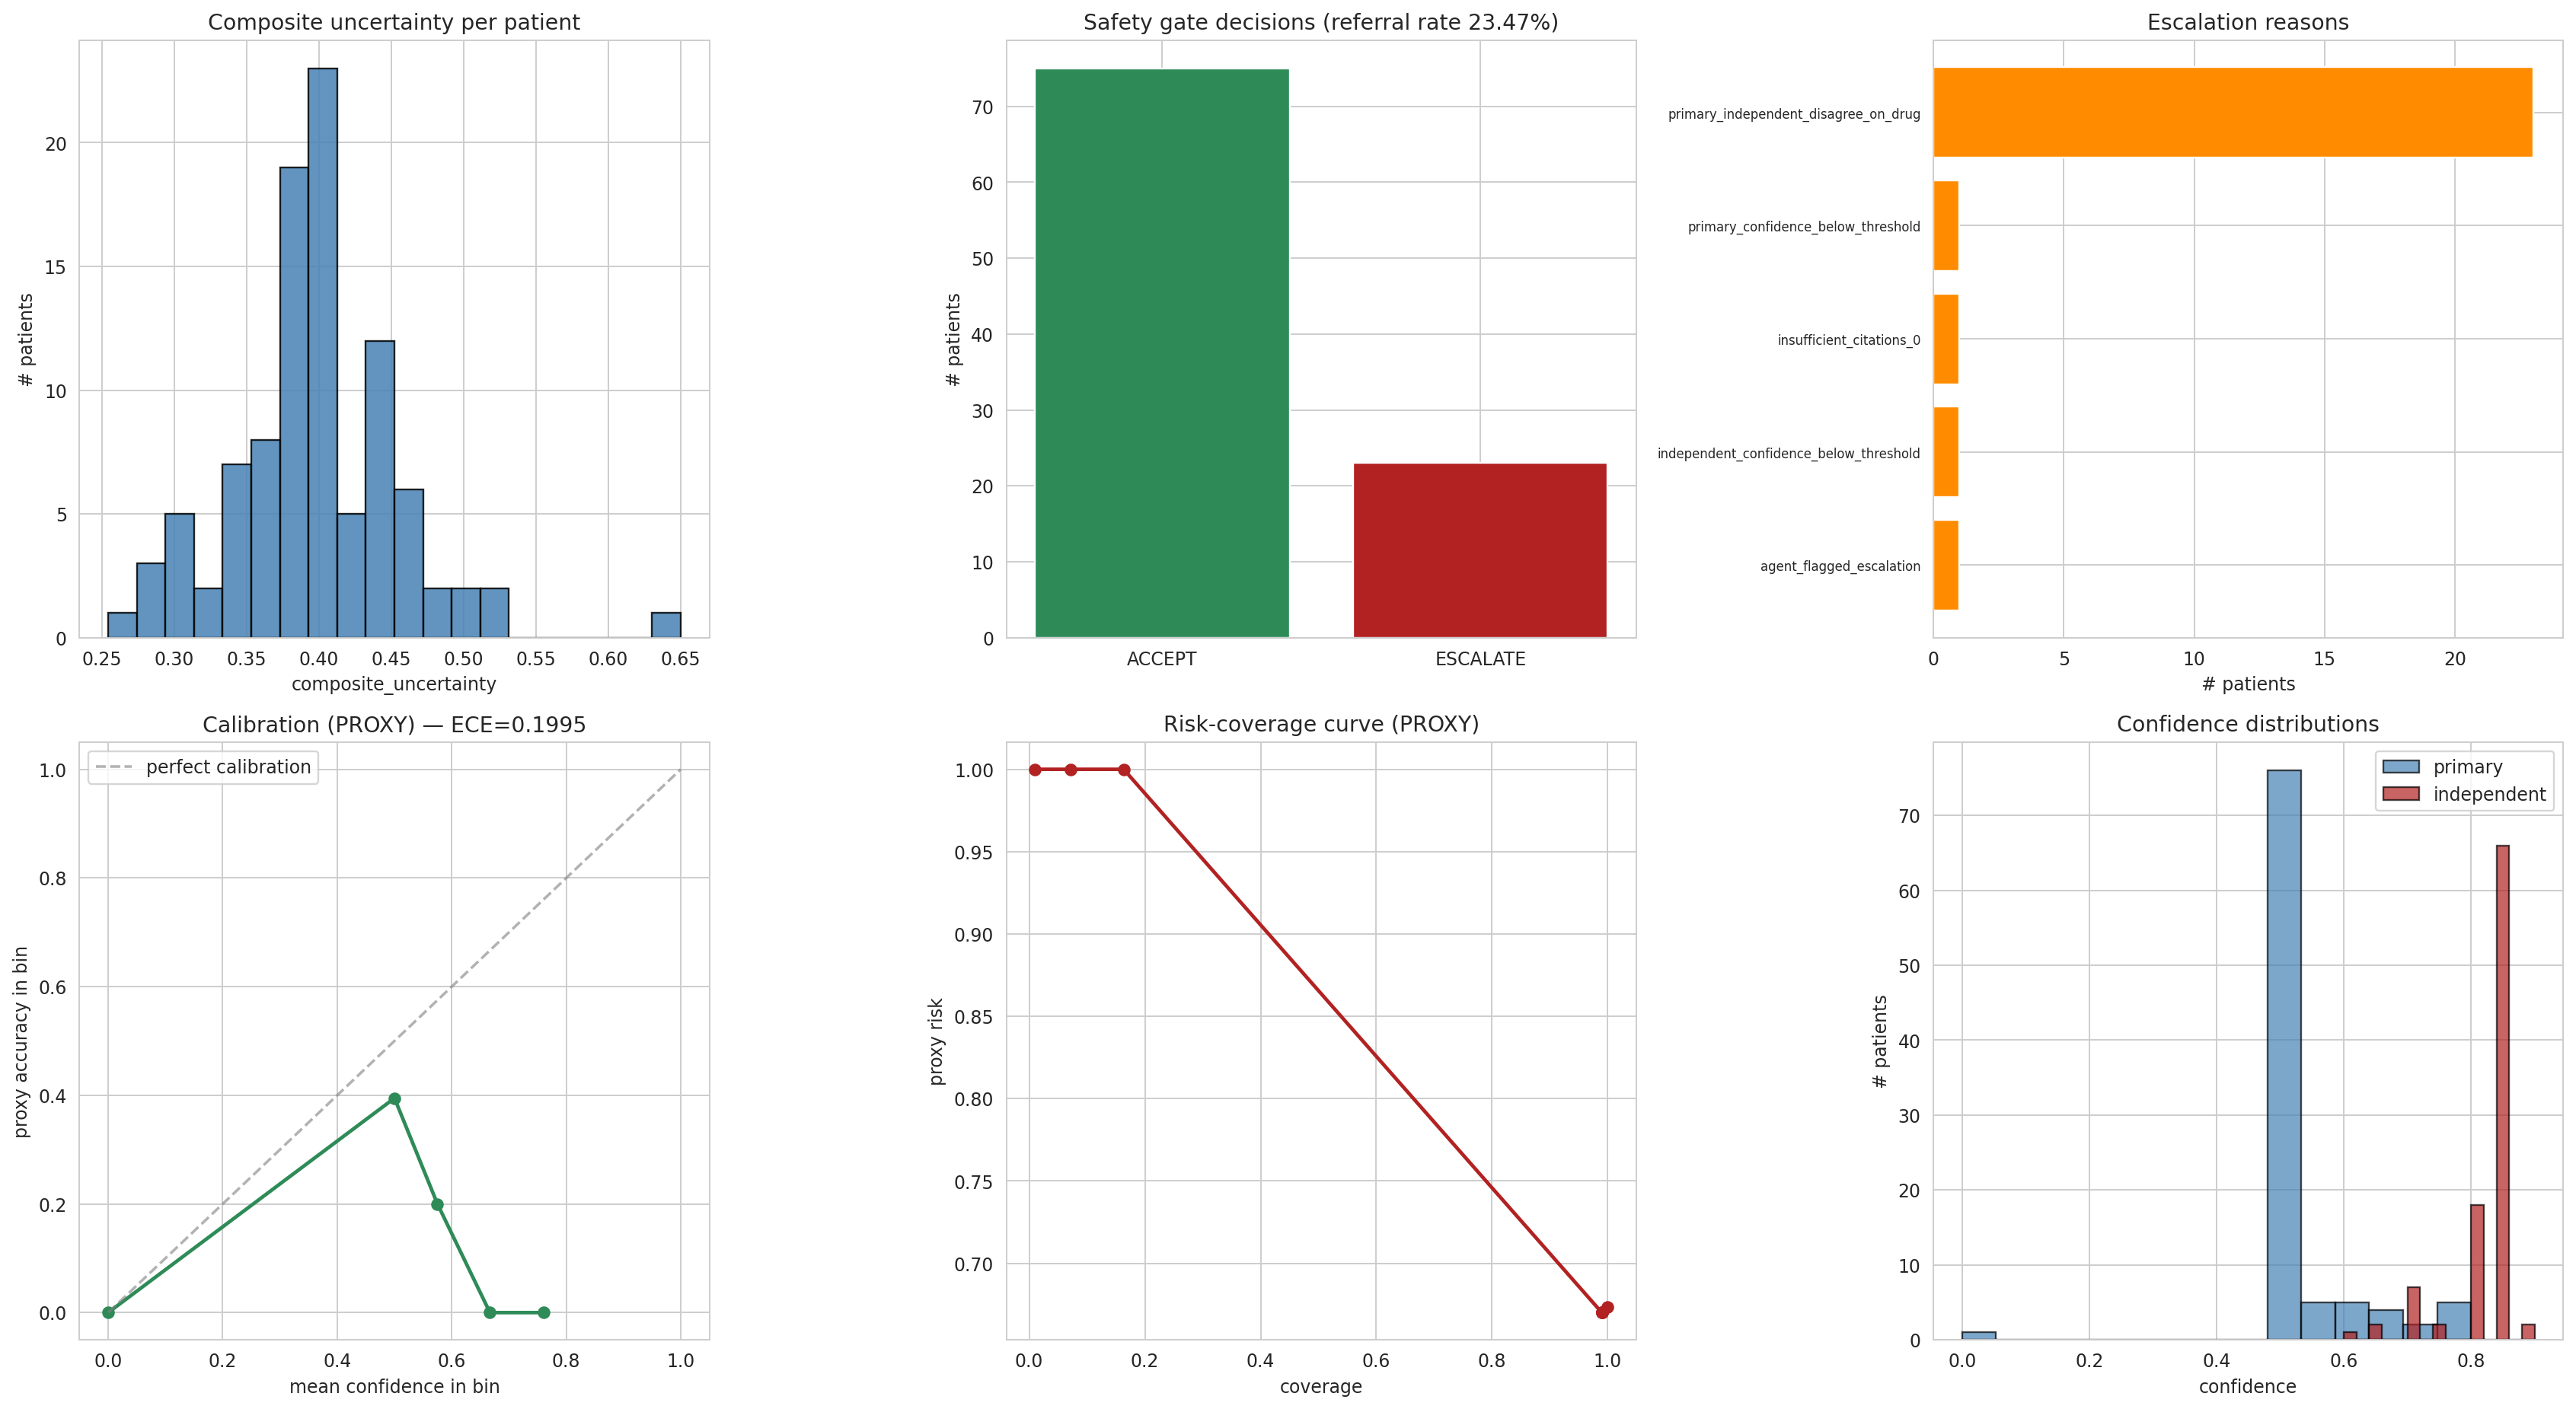

Saved: /kaggle/working/VERIONCO_outputs/08/safety_gate_dashboard.png


,metric,mean,median,std,min,max
0,primary_confidence,0.5260,0.5000,0.0883,0.0000,0.8000
1,independent_confidence,0.8227,0.8500,0.0552,0.6000,0.9000
2,agreement_score,0.4339,0.4667,0.1904,0.0000,0.6500
3,composite_uncertainty,0.3969,0.3958,0.0580,0.2542,0.6500
4,redteam_uncertainty,0.4150,0.5000,0.1574,0.0000,0.7500
5,conflict_burden,0.2016,0.1667,0.0957,0.0000,0.4167


In [12]:
# ============================================================
# DASHBOARD
# ============================================================
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from IPython.display import Image, display as _display

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. Composite uncertainty distribution
axes[0, 0].hist(uncertainty_df["composite_uncertainty"], bins=20,
                color="steelblue", alpha=0.85, edgecolor="black")
axes[0, 0].set_xlabel("composite_uncertainty")
axes[0, 0].set_ylabel("# patients")
axes[0, 0].set_title("Composite uncertainty per patient")

# 2. Safety gate decisions
decision_counts = gate_df["decision"].value_counts()
axes[0, 1].bar(decision_counts.index, decision_counts.values,
               color=["seagreen" if d == "ACCEPT" else "firebrick"
                      for d in decision_counts.index])
axes[0, 1].set_ylabel("# patients")
axes[0, 1].set_title(f"Safety gate decisions (referral rate {referral_rate:.2%})")

# 3. Escalation reasons
if reason_counts:
    reasons = list(reason_counts.keys())[:10]
    counts = [reason_counts[r] for r in reasons]
    axes[0, 2].barh(range(len(reasons)), counts, color="darkorange")
    axes[0, 2].set_yticks(range(len(reasons)))
    axes[0, 2].set_yticklabels(reasons, fontsize=7)
    axes[0, 2].invert_yaxis()
    axes[0, 2].set_xlabel("# patients")
    axes[0, 2].set_title("Escalation reasons")
else:
    axes[0, 2].text(0.5, 0.5, "No escalations", ha="center", va="center")
    axes[0, 2].set_title("Escalation reasons")

# 4. Calibration plot (confidence vs proxy accuracy)
bin_df = pd.DataFrame(proxy_bin_stats)
bin_df_valid = bin_df[bin_df["n"] > 0]
if len(bin_df_valid):
    axes[1, 0].plot(bin_df_valid["mean_conf"], bin_df_valid["accuracy"],
                    marker="o", color="seagreen", linewidth=2)
    axes[1, 0].plot([0, 1], [0, 1], "--", color="gray", alpha=0.6,
                    label="perfect calibration")
    axes[1, 0].set_xlabel("mean confidence in bin")
    axes[1, 0].set_ylabel("proxy accuracy in bin")
    axes[1, 0].set_title(f"Calibration (PROXY) — ECE={proxy_ece:.4f}")
    axes[1, 0].legend()
else:
    axes[1, 0].text(0.5, 0.5, "No data", ha="center", va="center")

# 5. Risk-coverage curve
rc_df = pd.DataFrame(risk_coverage)
rc_valid = rc_df[rc_df["proxy_risk"].notna()]
if len(rc_valid):
    axes[1, 1].plot(rc_valid["coverage"], rc_valid["proxy_risk"],
                    marker="o", color="firebrick", linewidth=2)
    axes[1, 1].set_xlabel("coverage")
    axes[1, 1].set_ylabel("proxy risk")
    axes[1, 1].set_title("Risk-coverage curve (PROXY)")
else:
    axes[1, 1].text(0.5, 0.5, "No data", ha="center", va="center")

# 6. Confidence distributions
axes[1, 2].hist(uncertainty_df["primary_confidence"].dropna(), bins=15,
                alpha=0.7, label="primary", color="steelblue", edgecolor="black")
axes[1, 2].hist(uncertainty_df["independent_confidence"].dropna(), bins=15,
                alpha=0.7, label="independent", color="firebrick", edgecolor="black")
axes[1, 2].set_xlabel("confidence")
axes[1, 2].set_ylabel("# patients")
axes[1, 2].set_title("Confidence distributions")
axes[1, 2].legend()

plt.tight_layout()
dash = NB_OUTPUT / "safety_gate_dashboard.png"
plt.savefig(dash, dpi=170, bbox_inches="tight")
_display(Image(filename=str(dash)))
plt.close(fig)
print("Saved:", dash)

# Summary table for paper
summary_rows = []
for col in ["primary_confidence", "independent_confidence",
            "agreement_score", "composite_uncertainty",
            "redteam_uncertainty", "conflict_burden"]:
    if col in uncertainty_df.columns:
        summary_rows.append({
            "metric": col,
            "mean":   round(float(uncertainty_df[col].mean()), 4),
            "median": float(uncertainty_df[col].median()),
            "std":    round(float(uncertainty_df[col].std()), 4),
            "min":    float(uncertainty_df[col].min()),
            "max":    float(uncertainty_df[col].max()),
        })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(NB_OUTPUT / "uncertainty_distribution_summary.csv", index=False)
display(summary_df)

In [13]:
import gc
# ============================================================
# OUTPUTS — Final inventory, zip, and completion banner
# ============================================================
import shutil
from pathlib import Path

outputs = []
for p in sorted(NB_OUTPUT.rglob("*")):
    if p.is_file():
        outputs.append({
            "file":       str(p.relative_to(NB_OUTPUT)),
            "size_bytes": p.stat().st_size,
        })

inventory_df = pd.DataFrame(outputs)
display(inventory_df)

total_size_mb = inventory_df["size_bytes"].sum() / (1024 * 1024) if len(inventory_df) else 0
print(f"\nTotal files:       {len(inventory_df)}")
print(f"Total size:        {total_size_mb:.2f} MB")
print(f"Output directory:  {NB_OUTPUT}")

zip_stem = OUTPUT_ROOT / "08_artifacts"
zip_path = Path(str(zip_stem) + ".zip")

if zip_path.exists():
    zip_path.unlink()
    print(f"Removed old zip: {zip_path.name}")

shutil.make_archive(
    base_name=str(zip_stem),
    format="zip",
    root_dir=str(NB_OUTPUT),
)

zip_size_mb = zip_path.stat().st_size / (1024 * 1024)
print(f"\n✓ Zipped artifacts")
print(f"  Path:  {zip_path}")
print(f"  Size:  {zip_size_mb:.2f} MB")

print("\n" + "=" * 50)
print("VERIONCO NOTEBOOK 08 COMPLETE")
print("=" * 50)
print(f"Artifacts:      {NB_OUTPUT}")
print(f"Archive:        {zip_path}")
print(f"Accept:         {n_accept} / {len(gate_df)}")
print(f"Escalate:       {n_escalate} / {len(gate_df)}")
print(f"Referral rate:  {referral_rate:.4f}")
print(f"Proxy ECE:      {proxy_ece:.4f}")
print(f"Proxy Brier:    {proxy_brier:.4f}")
print(f"Files in zip:   {len(inventory_df)}")
print(f"Zip size:       {zip_size_mb:.2f} MB")
print("=" * 50)

gc.collect()

,file,size_bytes
0,calibration_bins.csv,326
1,calibration_data.csv,2774
2,mdt_review_packets/TCGA-05-4244.json,5276
3,mdt_review_packets/TCGA-05-4249.json,5200
4,mdt_review_packets/TCGA-05-4250.json,4475
...,...,...
223,uncertainty_per_patient/TCGA-44-A47G.json,671
224,uncertainty_per_patient/TCGA-44-A4SS.json,680
225,uncertainty_per_patient/TCGA-44-A4SU.json,676
226,uncertainty_per_patient/TCGA-49-4487.json,680



Total files:       228
Total size:        0.50 MB
Output directory:  /kaggle/working/VERIONCO_outputs/08

✓ Zipped artifacts
  Path:  /kaggle/working/VERIONCO_outputs/08_artifacts.zip
  Size:  0.33 MB

VERIONCO NOTEBOOK 08 COMPLETE
Artifacts:      /kaggle/working/VERIONCO_outputs/08
Archive:        /kaggle/working/VERIONCO_outputs/08_artifacts.zip
Accept:         75 / 98
Escalate:       23 / 98
Referral rate:  0.2347
Proxy ECE:      0.1995
Proxy Brier:    0.2824
Files in zip:   228
Zip size:       0.33 MB


19

In [14]:
print(f"ACCEPT:   {n_accept} / {len(gate_df)}")
print(f"ESCALATE: {n_escalate} / {len(gate_df)}")
print(f"Referral rate: {referral_rate:.4f}")
print("\nReason frequency:")
for reason, count in reason_counts.most_common():
    print(f"  {reason}: {count}")

ACCEPT:   75 / 98
ESCALATE: 23 / 98
Referral rate: 0.2347

Reason frequency:
  primary_independent_disagree_on_drug: 23
  primary_confidence_below_threshold: 1
  insufficient_citations_0: 1
  independent_confidence_below_threshold: 1
  agent_flagged_escalation: 1


In [15]:
# Print citations from 5 patients
import json
for pid in sorted(patient_set)[:5]:
    orch = orchestration.get(pid, {})
    prim = orch.get("primary_recommendation", {})
    cits = prim.get("supporting_citations", [])
    print(f"\n=== {pid} ({len(cits)} citations) ===")
    for c in cits:
        print(f"  {repr(c)}")


=== TCGA-05-4244 (3 citations) ===
  'civic:78'
  'pubmed:25695224'
  'guideline:asco_stage4_driver_2026.pdf:0114'

=== TCGA-05-4245 (2 citations) ===
  'guideline:nice_ng122:platinum_doublet'
  'pubmed:41544598'

=== TCGA-05-4249 (2 citations) ===
  'civic:78'
  'pubmed:25695224'

=== TCGA-05-4250 (2 citations) ===
  'civic:78'
  'pubmed:25695224'

=== TCGA-05-4382 (3 citations) ===
  'guideline:esmo_mnsclc_2025:standard_of_care'
  'guideline:asco_stage4_driver_2026.pdf:0114'
  'pubmed:30593165'


In [16]:
print("Escalation reasons for the 23 referred cases:")
print()
for pid, rec in gate_records.items():
    if rec["decision"] == "ESCALATE":
        print(f"  {pid}: {'; '.join(rec['reasons'])}")

print("\n--- Reason frequency across all escalations ---")
all_r = []
for r in gate_records.values():
    all_r.extend(r["reasons"])
from collections import Counter
for reason, count in Counter(all_r).most_common():
    print(f"  {reason}: {count}")

Escalation reasons for the 23 referred cases:

  TCGA-05-4244: primary_independent_disagree_on_drug
  TCGA-05-4249: primary_independent_disagree_on_drug
  TCGA-05-4250: primary_independent_disagree_on_drug
  TCGA-05-4397: primary_independent_disagree_on_drug
  TCGA-05-4403: primary_confidence_below_threshold; primary_independent_disagree_on_drug; insufficient_citations_0
  TCGA-05-4410: primary_independent_disagree_on_drug
  TCGA-05-4415: primary_independent_disagree_on_drug
  TCGA-05-4417: primary_independent_disagree_on_drug
  TCGA-05-4434: primary_independent_disagree_on_drug
  TCGA-05-5423: primary_independent_disagree_on_drug
  TCGA-05-5428: primary_independent_disagree_on_drug
  TCGA-05-5715: primary_independent_disagree_on_drug
  TCGA-35-3615: primary_independent_disagree_on_drug
  TCGA-38-4632: independent_confidence_below_threshold; primary_independent_disagree_on_drug
  TCGA-38-6178: primary_independent_disagree_on_drug
  TCGA-44-2656: primary_independent_disagree_on_drug
  T

In [ ]:
# ============================================================
# EXPORT & DOWNLOAD ARTIFACT BUNDLE
# ============================================================
import shutil
from pathlib import Path
try:
    from IPython.display import FileLink, display
except ImportError:
    def FileLink(p): return p
    def display(*a): pass

export_dir = OUTPUT_ROOT / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)
zip_name = f'verionco_outputs_{NB_OUTPUT.name}'
zip_path = export_dir / zip_name

# Package NB_OUTPUT into zip
shutil.make_archive(str(zip_path), 'zip', NB_OUTPUT)
final_zip = export_dir / f'{zip_name}.zip'

print('=' * 60)
print(f'VERIONCO NOTEBOOK {NB_OUTPUT.name} COMPLETE')
print(f'Artifact bundle created: {final_zip}')
print(f'Archive size: {final_zip.stat().st_size / (1024*1024):.2f} MB')
print('=' * 60)

# Display download link (clickable in Kaggle/Jupyter)
display(FileLink(str(final_zip)))
